<a href="https://colab.research.google.com/github/tanishgupta1211/college-complaint-classification/blob/main/notebooks/01_project_setup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# College Complaint Classification System

## Project Overview

This project aims to automatically classify college student complaints into relevant categories using Natural Language Processing (NLP) and Machine Learning.

## Objectives
- Collect and analyze a suitable complaint dataset.
- Preprocess English and Hindi/Hinglish complaint text.
- Convert text into numerical features using TF-IDF.
- Train and compare machine learning classification models.
- Evaluate model performance using accuracy, precision, recall, and F1-score.
- Predict the category of a new complaint.

## Tools and Technologies
- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- GitHub

## Project Workflow
1. Dataset collection
2. Data exploration and cleaning
3. Text preprocessing
4. Feature extraction
5. Model training
6. Model evaluation
7. Complaint prediction

**Project Status:** Day 1 — Project Setup

In [16]:

# Import the libraries we need

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset


In [17]:

# Load the college complaint data

dataset = load_dataset("alaminxpro/university-students-complaints")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))


Training rows: 273
Testing rows: 59


In [18]:

# Count complaints in each category

category_counts = train_df["Category"].value_counts()
print(category_counts)


Category
Infrastructure    114
Technical          58
Academic           48
Finance            29
Administrative     24
Name: count, dtype: int64


In [19]:

# Check for missing and duplicate data

print("Missing values:")
print(train_df.isnull().sum())

print("\nDuplicate rows:", train_df.duplicated().sum())

print(
    "Empty complaints:",
    train_df["Complaint_Description"].fillna("").str.strip().eq("").sum()
)


Missing values:
ID                         0
Timestamp                  0
Gender                     0
Semester                   0
Student_Dept               0
Complaint_Description      0
Category                   0
Responsible_Departments    0
Primary_Department         0
Aspects                    0
Severity                   0
Complaint_Group_ID         0
dtype: int64

Duplicate rows: 0
Empty complaints: 0


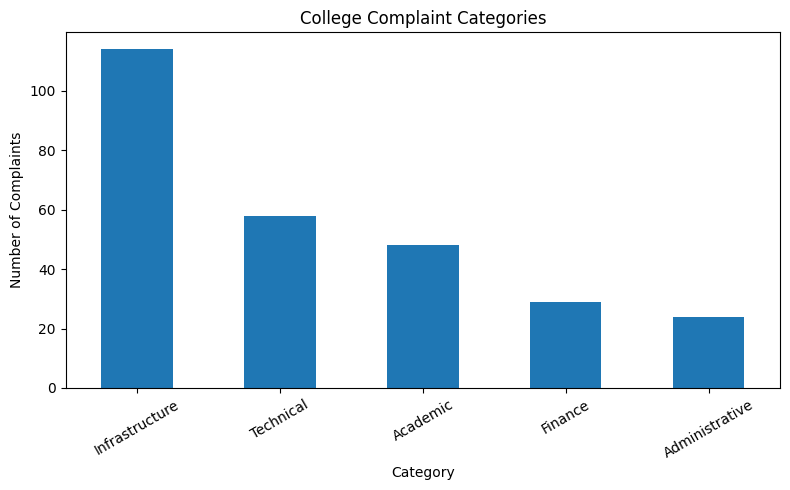

In [20]:

# Plot the complaint categories

category_counts.plot(kind="bar", figsize=(8, 5))

plt.title("College Complaint Categories")
plt.xlabel("Category")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [21]:

print(train_df.shape)
print(test_df.shape)


(273, 12)
(59, 12)


In [22]:
train_df["Complaint_Group_ID"].value_counts().head(10)

,count
Complaint_Group_ID,
20,8
11,4
4,4
8,4
23,4
21,4
19,4
12,4
3,4


In [23]:

train_groups = set(train_df["Complaint_Group_ID"])
test_groups = set(test_df["Complaint_Group_ID"])

common_groups = train_groups.intersection(test_groups)

print("Unique groups in training:", len(train_groups))
print("Unique groups in testing:", len(test_groups))
print("Groups present in both:", len(common_groups))


Unique groups in training: 153
Unique groups in testing: 33
Groups present in both: 0


In [24]:

# Check complaints from group 20

group_data = train_df[train_df["Complaint_Group_ID"] == 20]

display(group_data[["Complaint_Description", "Category"]])


,Complaint_Description,Category
14,We need more research facilities in our univer...,Academic
16,We need more research facilities in our univer...,Academic
64,We would benefit from more research facilities...,Academic
67,We require more research facilities in our uni...,Academic
119,We are in need of more research facilities in ...,Academic
121,We would benefit from more research facilities...,Academic
170,We require more research facilities in our uni...,Academic
171,We are in need of more research facilities in ...,Academic


In [25]:

# Check complaints from group 20

group_data = train_df[train_df["Complaint_Group_ID"] == 20]

display(group_data[["Complaint_Description", "Category"]])


,Complaint_Description,Category
14,We need more research facilities in our univer...,Academic
16,We need more research facilities in our univer...,Academic
64,We would benefit from more research facilities...,Academic
67,We require more research facilities in our uni...,Academic
119,We are in need of more research facilities in ...,Academic
121,We would benefit from more research facilities...,Academic
170,We require more research facilities in our uni...,Academic
171,We are in need of more research facilities in ...,Academic


In [26]:

# Count complaints in each group

group_counts = train_df["Complaint_Group_ID"].value_counts()

print("Total groups:", len(group_counts))
print("Groups with multiple complaints:", (group_counts > 1).sum())
print("Largest group size:", group_counts.max())


Total groups: 153
Groups with multiple complaints: 46
Largest group size: 8


In [27]:

# Check categories within each group

cat_per_group = train_df.groupby("Complaint_Group_ID")["Category"].nunique()

print("Groups with different categories:", (cat_per_group > 1).sum())
print("Groups with one category:", (cat_per_group == 1).sum())


Groups with different categories: 0
Groups with one category: 153


In [28]:

# Check categories in test groups

test_cats = test_df.groupby("Complaint_Group_ID")["Category"].nunique()

print("Test groups with different categories:", (test_cats > 1).sum())
print("Test groups with one category:", (test_cats == 1).sum())


Test groups with different categories: 0
Test groups with one category: 33


## Day 2: Complaint Group Analysis

### Objective
Understand complaint groups and check whether related complaints are separated between training and testing data.

### Work Completed
- Checked complaint counts for each `Complaint_Group_ID`.
- Inspected complaints from Group 20.
- Checked category consistency within training and testing groups.
- Checked for common group IDs between training and testing data.

### Findings
- Training data contains 153 unique groups.
- Testing data contains 33 unique groups.
- 46 training groups contain multiple complaints.
- The largest training group contains 8 complaints.
- All 153 training groups have consistent categories.
- All 33 testing groups have consistent categories.
- No group IDs are shared between training and testing data.

### Conclusion
The group IDs are useful for analysing related complaints. No group overlap was found between the training and testing sets, which reduces the risk of leakage through shared groups.

### Next Step
Prepare complaint text for machine learning and explore text preprocessing techniques.